0. Porque modelos basados en arboles?
- Mayoria de categorias son binarias
- Probable que churn dependa de varios factores, no solo de 'tenure' por ejemplo
    Cada split depende de los splits anteriores --> modelo lineal requiere mas trabajo
- RF y XGB dan feature importance --> que variables pesan mas a la hora de predecir una baja

1. librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (classification_report, f1_score, precision_score,
                              recall_score, accuracy_score, roc_auc_score,
                              confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

2. Cargar los datos preprocesados (train-test)

In [2]:
X_train = pd.read_csv('../data/X_train.csv')
X_test = pd.read_csv('../data/X_test.csv')
y_train = pd.read_csv('../data/y_train.csv').squeeze()
y_test = pd.read_csv('../data/y_test.csv').squeeze()

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 19), (1409, 19), (5634,), (1409,))

3. Entrenar modelos

In [3]:
modelos = {
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
}

resultados = []
preds_dict = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    preds_dict[nombre] = (y_pred, y_proba)
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

resultados_df = pd.DataFrame(resultados).sort_values('F1-score', ascending=False)
resultados_df

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,XGBoost,0.790632,0.622291,0.537433,0.576758,0.818997
1,Random Forest,0.793471,0.642612,0.500000,0.562406,0.824010
0,Árbol de Decisión,0.721079,0.475703,0.497326,0.486275,0.649386


In [ ]:
modelos = {
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
}

resultados = []
preds_dict = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    preds_dict[nombre] = (y_pred, y_proba)
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

resultados_df = pd.DataFrame(resultados).sort_values('F1-score', ascending=False)
resultados_df

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,XGBoost,0.790632,0.622291,0.537433,0.576758,0.818997
1,Random Forest,0.793471,0.642612,0.500000,0.562406,0.824010
0,Árbol de Decisión,0.721079,0.475703,0.497326,0.486275,0.649386


Accuracy --> churn desbalanceado, modelo adivinaria no churn acertando 73%

F1 --> Obliga a aprender clase minoritaria

4. Elegir mejor modelo en base a F1- Score
buscar equilibrio entre precision (no marcar de mas) y recall (no dejar escapar clientes)

In [5]:
mejor_modelo_nombre = resultados_df.iloc[0]['Modelo']
mejor_modelo = modelos[mejor_modelo_nombre]
print(f'Mejor modelo: {mejor_modelo_nombre}')

Mejor modelo: XGBoost


5. Matriz de confusión del mejor modelo

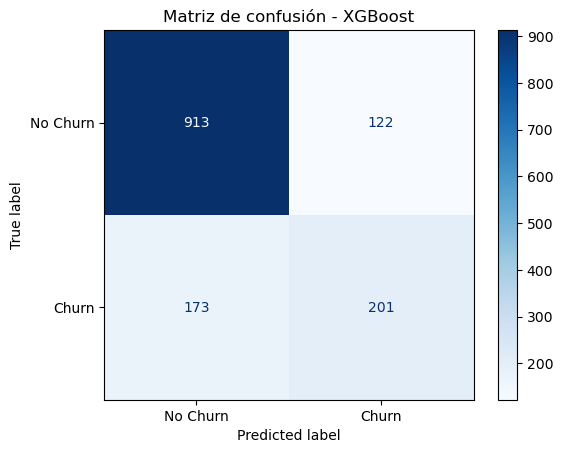

In [6]:
y_pred_mejor, y_proba_mejor = preds_dict[mejor_modelo_nombre]

cm = confusion_matrix(y_test, y_pred_mejor)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title(f'Matriz de confusión - {mejor_modelo_nombre}')
plt.show()

De los 374 clientes que se dieron de baja el modelo solo detecto 201 (recall: 53.7%). Casi la mitad de los cleintes que se iban a ir se escaparon sin ser detectados.Falsos Negativos

6. Reporte de clasificación completo

In [7]:
print(classification_report(y_test, y_pred_mejor, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.84      0.88      0.86      1035
       Churn       0.62      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



7. Feature Importance

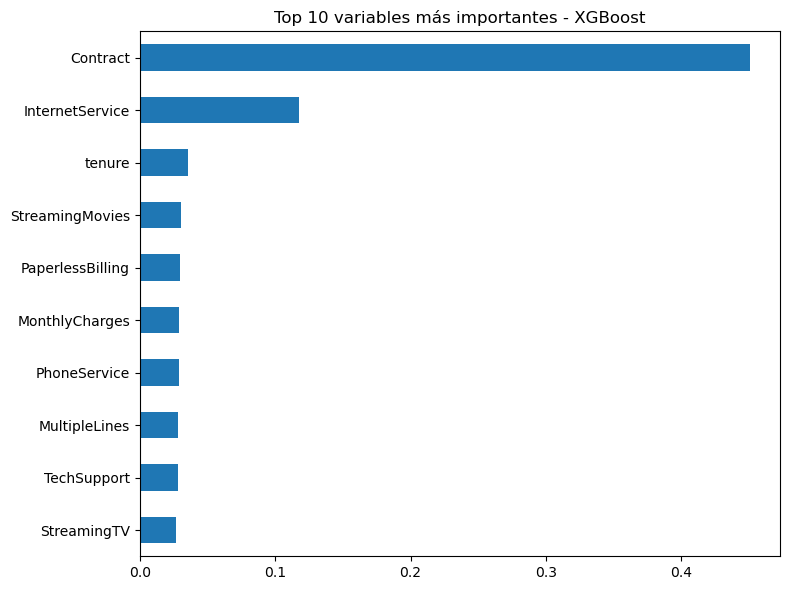

In [8]:
importancias = pd.Series(mejor_modelo.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
importancias.head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title(f'Top 10 variables más importantes - {mejor_modelo_nombre}')
plt.tight_layout()
plt.show()

8. Conclusiones
- Mejor modelo:XGBoost (0.577 F1)
- Variables mas determinantes del churn: 'Contract', 'Internet Service' y 'Tenure'
- Trade-off precision/recall del mejor modelo: 173 clientes que el modelo predijo que se quedarían pero se fueron. 
- Posibles siguientes pasos: ajuste de hiperparametros, había mucha desigualdad en los datos en cuanto al churn. 73%-27%, el modelo tiende a adivinar al azar ya que esto le da una buena media de puntuación.

9. En un futuro

- Balancear la desigualdad Churn/no Churn, penalizar al modelo cuando falle un churn mas furte que cuando falle un no churn. 
- Dejar escapar a un cliente que se iba cuesta mas que retener a alguien que se quedaba.Encontrar punto de equilibrio entre precision y recall segun el coste de cada error, no 50-50 como hace F1-Score
- Feature Enguineering: Crear variables nuevas que combinen las existentes. EN EDA vimos que la relacion con churn parece depender de combinaciones, por ejemplo TotalCharges / Tenure --> gasto medio mensual.
- Feature Importance: Sabemos que variables importan mas pero no sabemos como afectan (Si hay mas tenure, hay mas o menos churn?) 